In [1]:
# import os
# import json
# import numpy as np
# import cv2
# import matplotlib.pyplot as plt
# from pycocotools import mask as maskUtils

# # ==========================
# # PATHS
# # ==========================
# IMAGE_DIR = "/home/dbtproject/barsha/Image/training_set/Class1_Incognita"
# JSON_PATH = "/home/dbtproject/barsha/np_code_new/annotations/instances_default.json"

# # ==========================
# # LOAD JSON
# # ==========================
# with open(JSON_PATH, 'r') as f:
#     coco = json.load(f)

# images = {img['id']: img for img in coco['images']}
# annotations = coco['annotations']

# # group annotations
# ann_dict = {}
# for ann in annotations:
#     ann_dict.setdefault(ann['image_id'], []).append(ann)

# # ==========================
# # DRAW OVERLAY FUNCTION
# # ==========================
# def draw_overlay(image, anns):

#     overlay = image.copy()

#     for ann in anns:

#         seg = ann.get("segmentation", [])

#         # =========================
#         # CASE 1: MASK (RLE)
#         # =========================
#         if isinstance(seg, dict) and "counts" in seg:
#             mask = maskUtils.decode(seg)

#             color = np.array([0, 255, 0])  # green mask

#             # apply transparent overlay
#             overlay[mask == 1] = (
#                 0.6 * overlay[mask == 1] + 0.4 * color
#             ).astype(np.uint8)

#         # =========================
#         # CASE 2: BBOX
#         # =========================
#         else:
#             x, y, w, h = map(int, ann['bbox'])

#             # draw rectangle
#             cv2.rectangle(
#                 overlay,
#                 (x, y),
#                 (x + w, y + h),
#                 (0, 255, 0),
#                 2
#             )

#     return overlay


# # ==========================
# # LOOP THROUGH IMAGES
# # ==========================
# for img_id, img_info in images.items():

#     img_path = os.path.join(IMAGE_DIR, img_info['file_name'])

#     if not os.path.exists(img_path):
#         continue

#     image = cv2.imread(img_path)
#     image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

#     anns = ann_dict.get(img_id, [])

#     overlay = draw_overlay(image, anns)

#     # ======================
#     # DISPLAY SIDE BY SIDE
#     # ======================
#     fig, ax = plt.subplots(1, 2, figsize=(12, 6))

#     # LEFT: Original
#     ax[0].imshow(image)
#     ax[0].set_title(f"Original\n{img_info['file_name']}")

#     # RIGHT: Overlay
#     ax[1].imshow(overlay)
#     ax[1].set_title("Annotation Overlay")

#     for a in ax:
#         a.axis("off")

#     plt.tight_layout()
#     plt.show()

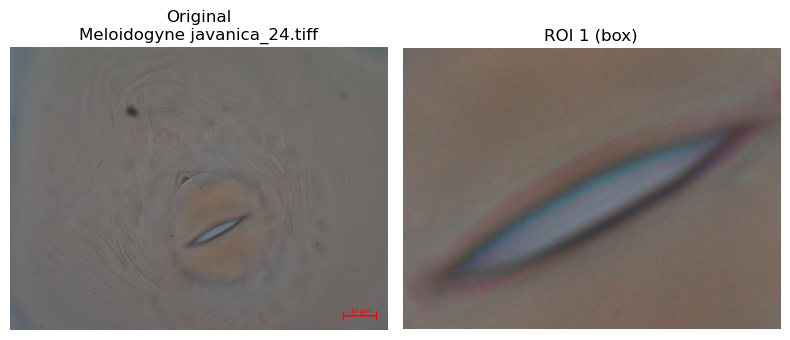

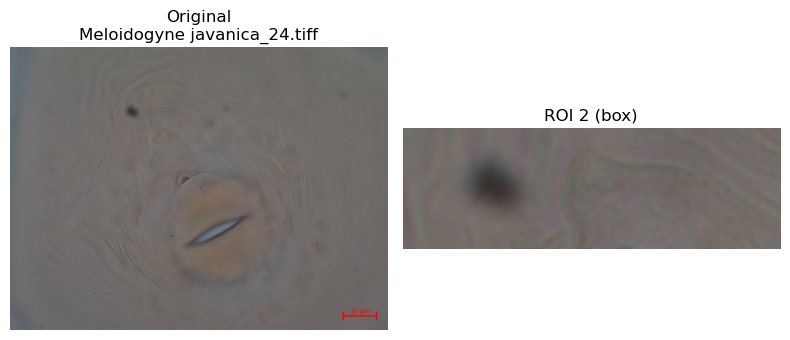

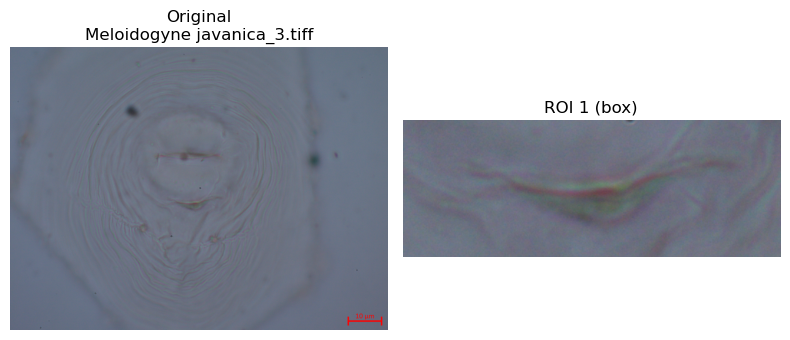

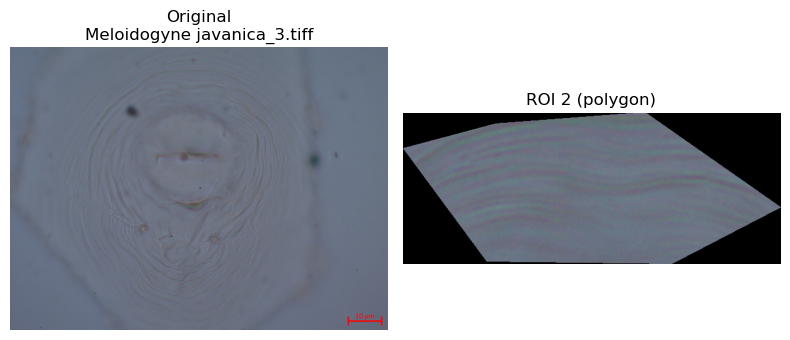

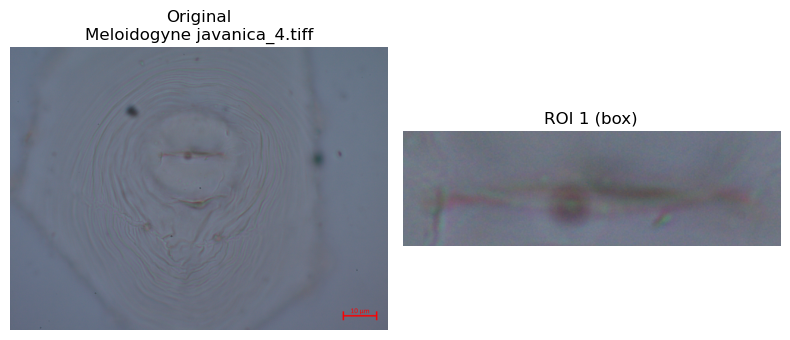

...

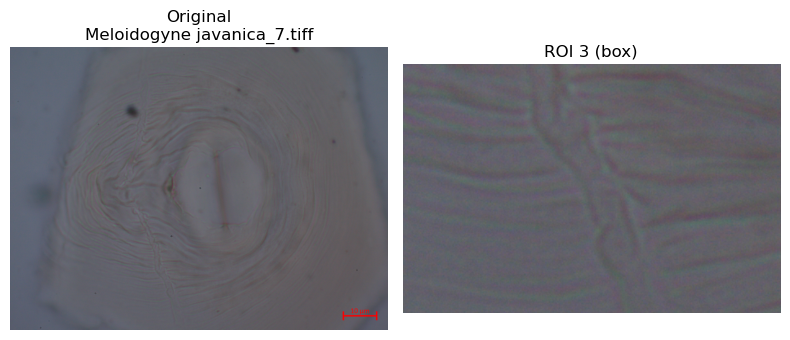

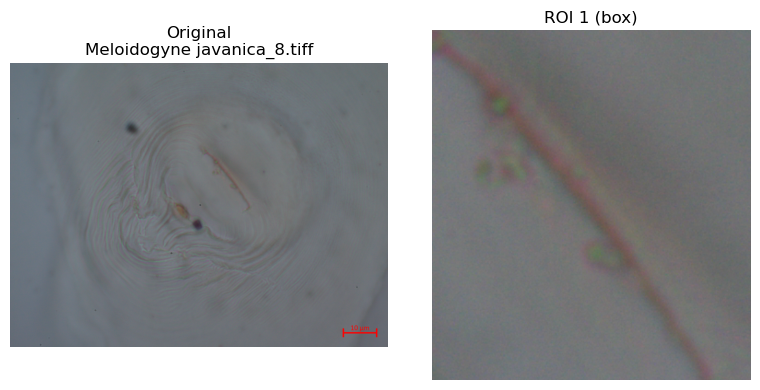

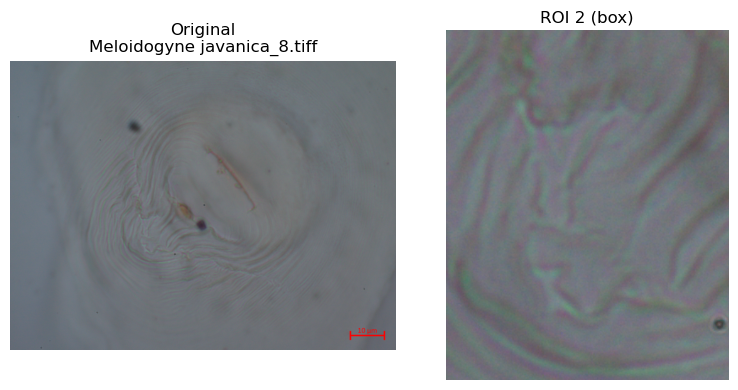

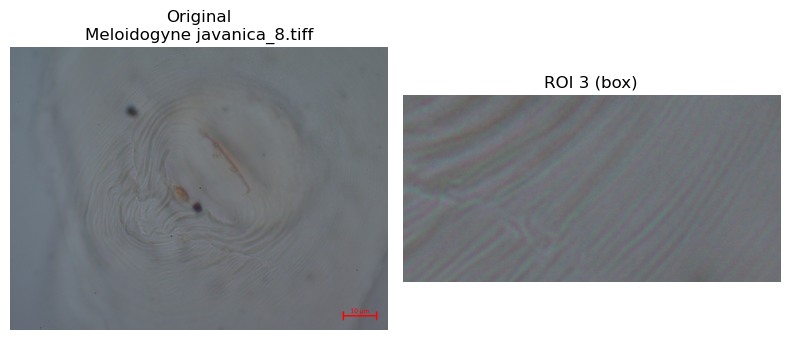

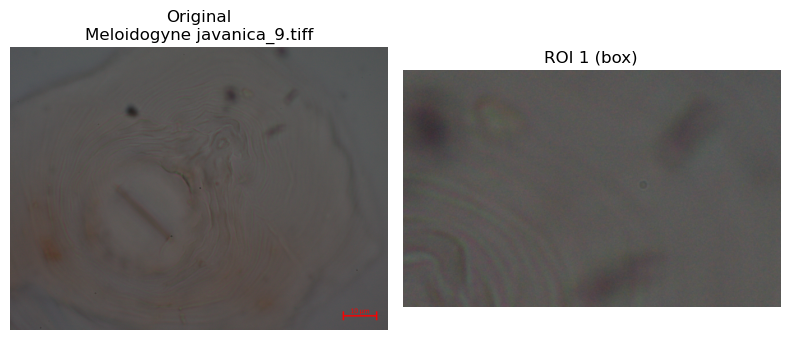

In [2]:
import os
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt


# PATHS

IMAGE_DIR = "/home/dbtproject/barsha/Image/training_set/Class2_Javanica"
XML_PATH = "/home/dbtproject/barsha/np_code_new/annotations.xml"


# LOAD XML

tree = ET.parse(XML_PATH)
root = tree.getroot()



# FUNCTION: EXTRACT ROI

def extract_roi(image, shape):

    H, W = image.shape[:2]

  
    # CASE 1: RECTANGLE
  
    if shape.tag == "box":
        xtl = int(float(shape.get("xtl")))
        ytl = int(float(shape.get("ytl")))
        xbr = int(float(shape.get("xbr")))
        ybr = int(float(shape.get("ybr")))

        roi = image[ytl:ybr, xtl:xbr]
        return roi

    # CASE 2: ELLIPSE
   
    elif shape.tag == "ellipse":
        cx = float(shape.get("cx"))
        cy = float(shape.get("cy"))
        rx = float(shape.get("rx"))
        ry = float(shape.get("ry"))

        mask = np.zeros((H, W), dtype=np.uint8)

        center = (int(cx), int(cy))
        axes = (int(rx), int(ry))

        cv2.ellipse(mask, center, axes, 0, 0, 360, 1, -1)

        ys, xs = np.where(mask == 1)

        if len(xs) == 0 or len(ys) == 0:
            return None

        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()

        crop_img = image[y1:y2+1, x1:x2+1]
        crop_mask = mask[y1:y2+1, x1:x2+1]

        roi = crop_img.copy()
        roi[crop_mask == 0] = 0

        return roi

    # CASE 3: POLYGON
    
    elif shape.tag == "polygon":
        points = shape.get("points")
        pts = []

        for p in points.split(";"):
            x, y = map(float, p.split(","))
            pts.append([int(x), int(y)])

        pts = np.array(pts, np.int32)

        mask = np.zeros((H, W), dtype=np.uint8)
        cv2.fillPoly(mask, [pts], 1)

        ys, xs = np.where(mask == 1)

        if len(xs) == 0 or len(ys) == 0:
            return None

        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()

        crop_img = image[y1:y2+1, x1:x2+1]
        crop_mask = mask[y1:y2+1, x1:x2+1]

        roi = crop_img.copy()
        roi[crop_mask == 0] = 0

        return roi

    return None



# LOOP THROUGH IMAGES

for image_tag in root.findall("image"):

    file_name = image_tag.get("name")
    img_path = os.path.join(IMAGE_DIR, file_name)

    if not os.path.exists(img_path):
        continue

    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Collect all shapes
    shapes = []
    shapes.extend(image_tag.findall("box"))
    shapes.extend(image_tag.findall("ellipse"))
    shapes.extend(image_tag.findall("polygon"))

    
    # PROCESS EACH ROI
   
    for i, shape in enumerate(shapes):

        roi = extract_roi(image, shape)

        if roi is None:
            continue

        # DISPLAY
       
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))

        ax[0].imshow(image)
        ax[0].set_title(f"Original\n{file_name}")

        ax[1].imshow(roi)
        ax[1].set_title(f"ROI {i+1} ({shape.tag})")

        for a in ax:
            a.axis("off")

        plt.tight_layout()
        plt.show()

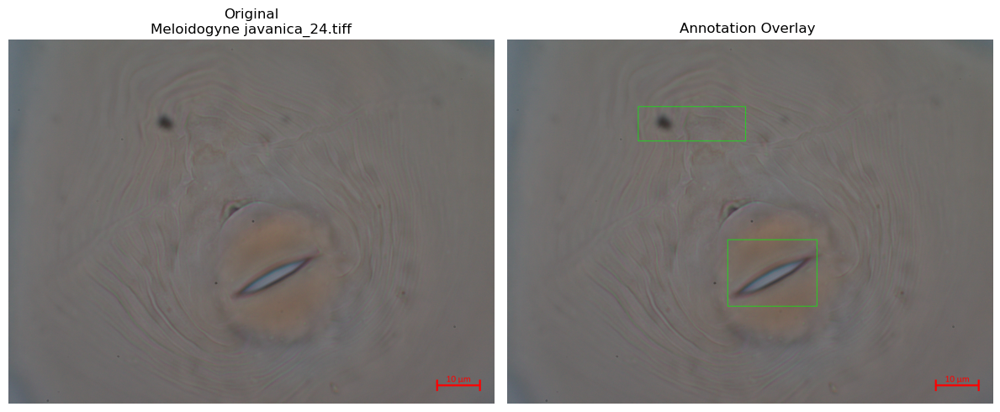

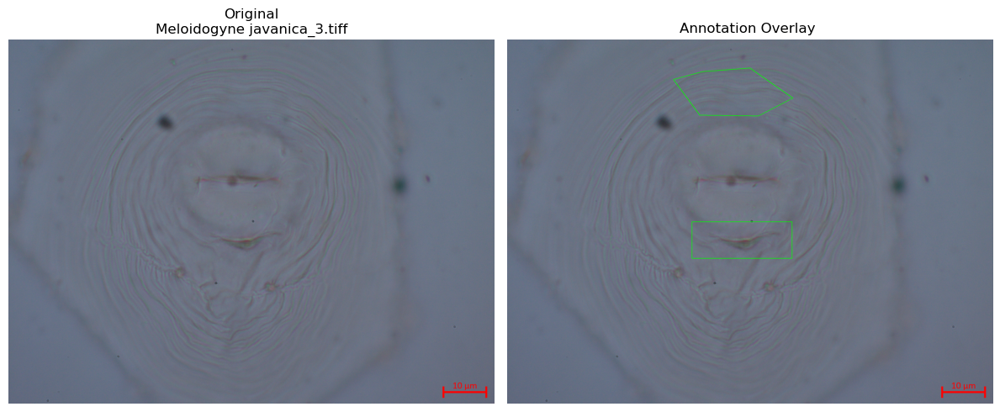

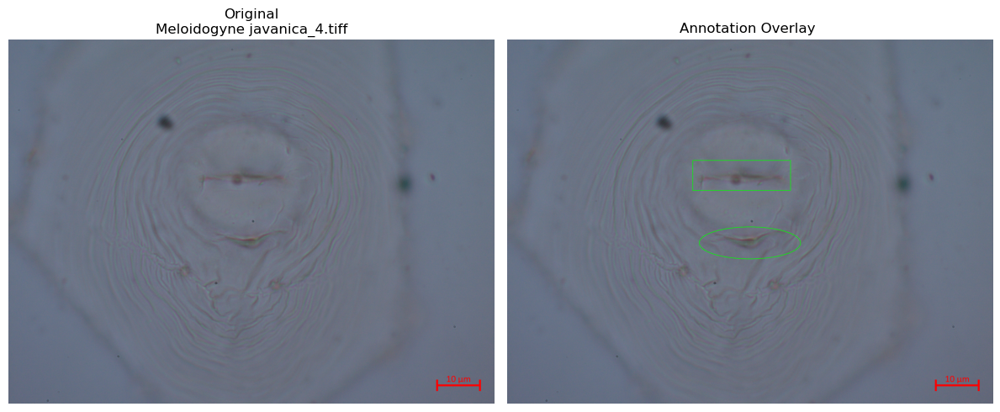

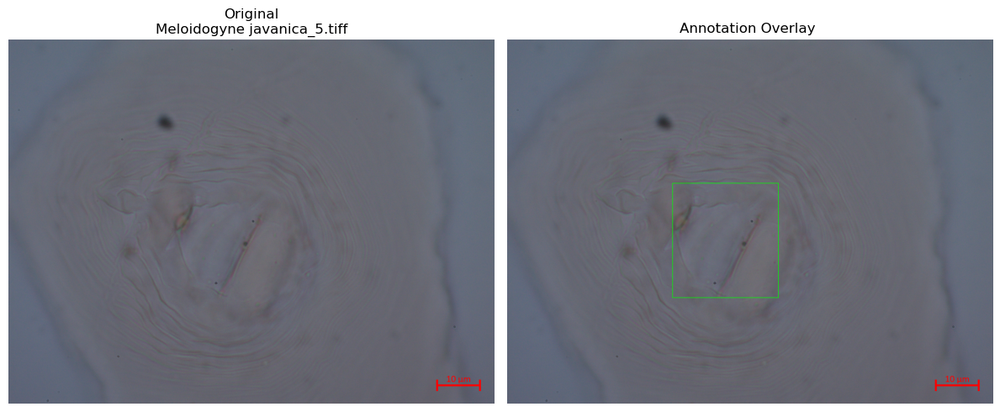

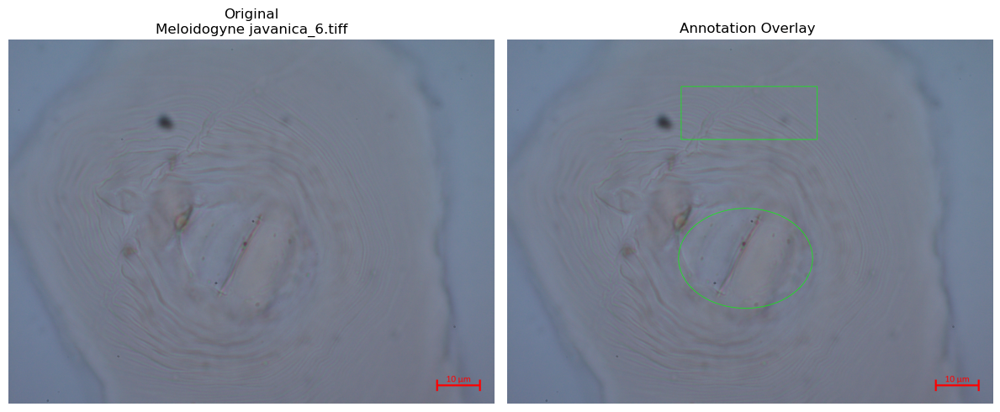

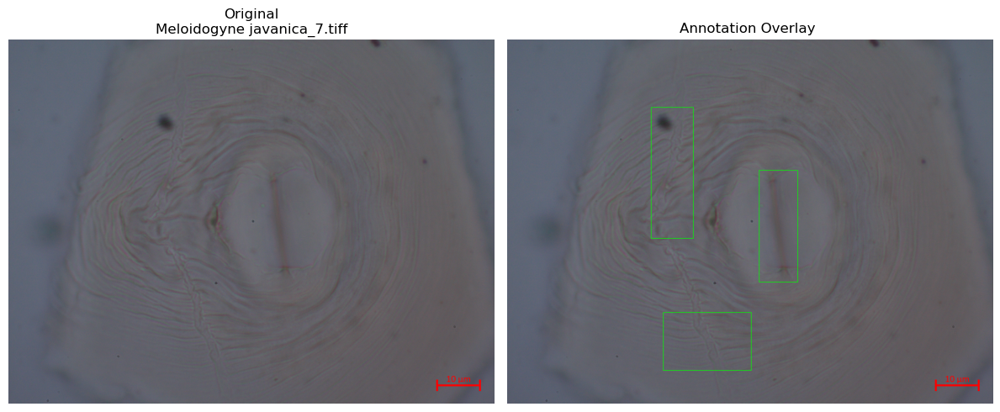

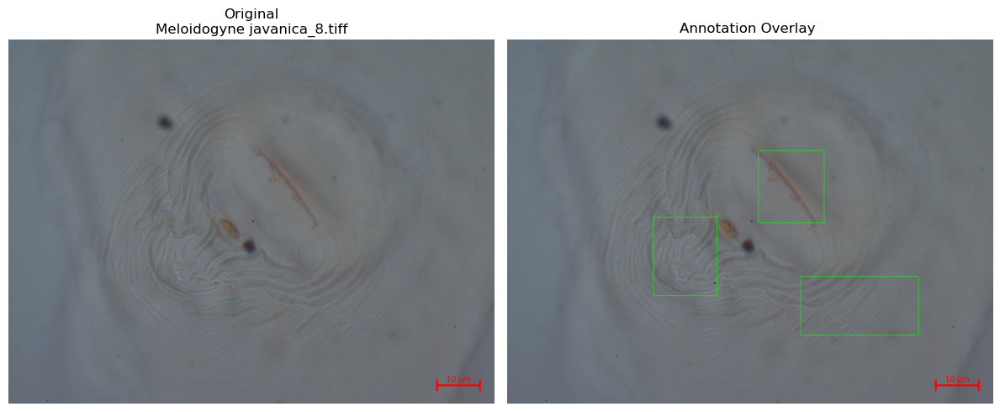

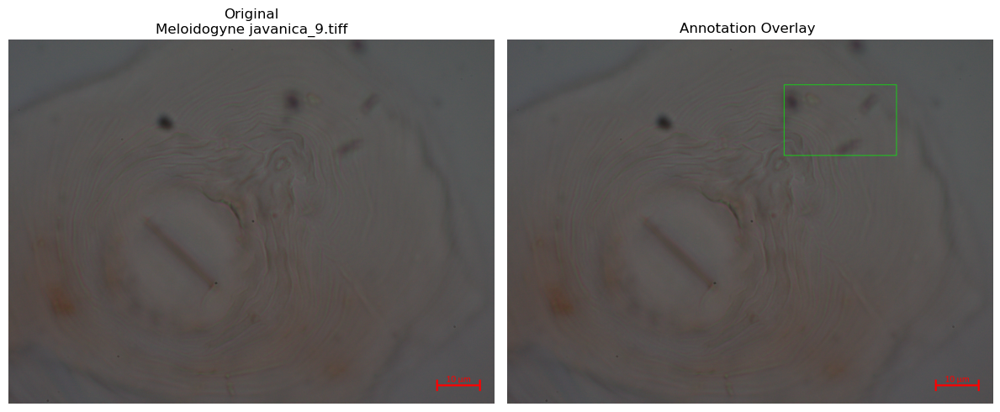

In [3]:
import os
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# PATHS

IMAGE_DIR = "/home/dbtproject/barsha/Image/training_set/Class2_Javanica"
XML_PATH = "/home/dbtproject/barsha/np_code_new/annotations.xml"

# LOAD XML

tree = ET.parse(XML_PATH)
root = tree.getroot()


# OVERLAY FUNCTION
def draw_overlay(image, image_tag):

    overlay = image.copy()

    # RECTANGLES --------
    for box in image_tag.findall("box"):
        xtl = int(float(box.get("xtl")))
        ytl = int(float(box.get("ytl")))
        xbr = int(float(box.get("xbr")))
        ybr = int(float(box.get("ybr")))

        cv2.rectangle(overlay, (xtl, ytl), (xbr, ybr), (0, 255, 0), 2)

    # ELLIPSES --------
    for ellipse in image_tag.findall("ellipse"):
        cx = float(ellipse.get("cx"))
        cy = float(ellipse.get("cy"))
        rx = float(ellipse.get("rx"))
        ry = float(ellipse.get("ry"))

        center = (int(cx), int(cy))
        axes = (int(rx), int(ry))

        cv2.ellipse(
            overlay,
            center,
            axes,
            angle=0,
            startAngle=0,
            endAngle=360,
            color=(0, 255, 0),
            thickness=2
        )

    # POLYGONS --------
    for poly in image_tag.findall("polygon"):
        points = poly.get("points")
        pts = []

        for p in points.split(";"):
            x, y = map(float, p.split(","))
            pts.append([int(x), int(y)])

        pts = np.array(pts, np.int32)

        cv2.polylines(overlay, [pts], isClosed=True, color=(0,255,0), thickness=2)

    return overlay


# LOOP THROUGH IMAGES

for image_tag in root.findall("image"):

    file_name = image_tag.get("name")
    img_path = os.path.join(IMAGE_DIR, file_name)

    if not os.path.exists(img_path):
        continue

    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    overlay = draw_overlay(image, image_tag)


    # DISPLAY

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    ax[0].imshow(image)
    ax[0].set_title(f"Original\n{file_name}")

    ax[1].imshow(overlay)
    ax[1].set_title("Annotation Overlay ")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

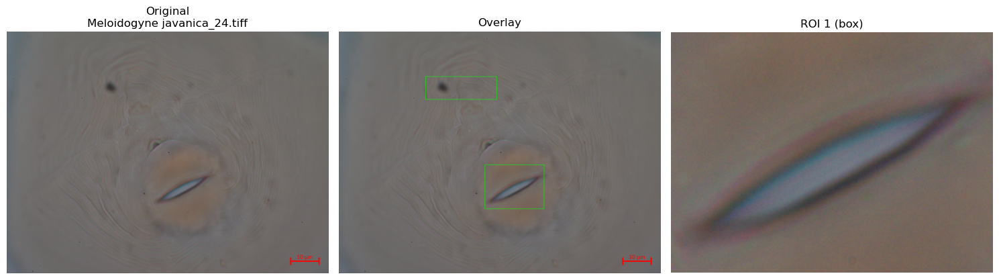

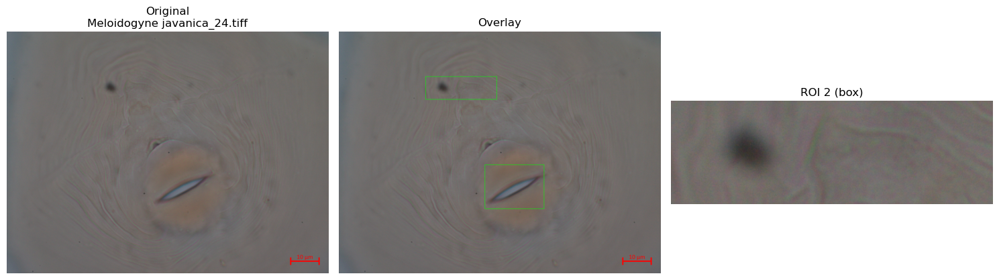

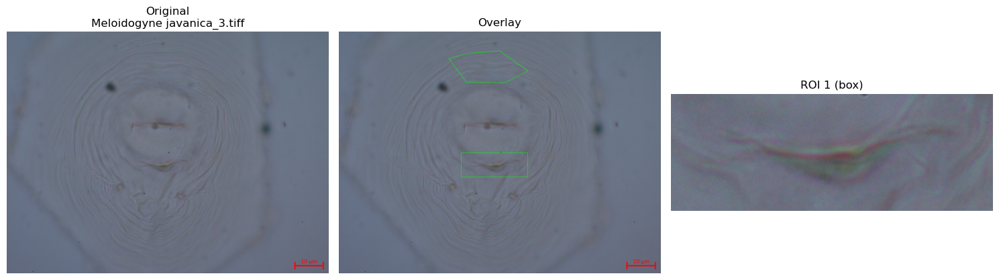

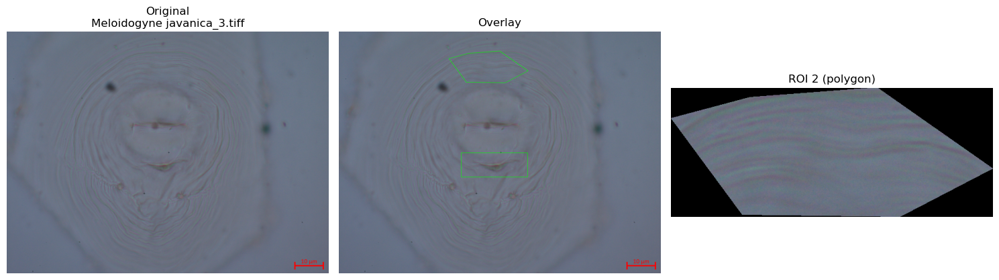

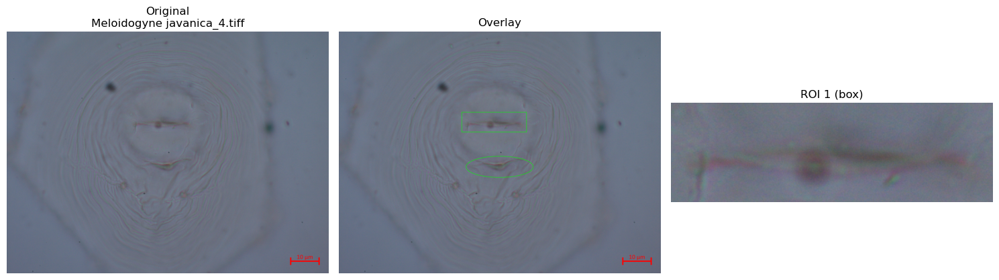

...

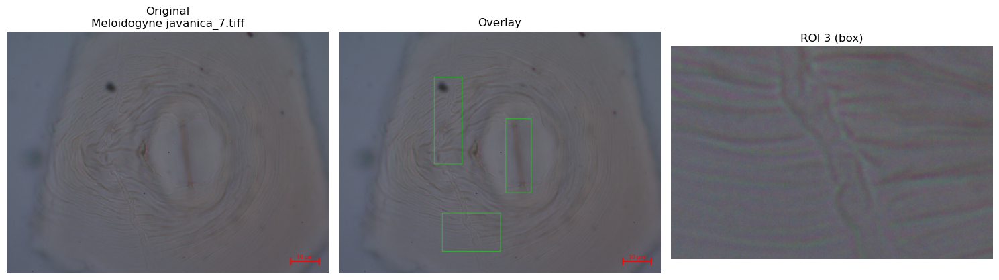

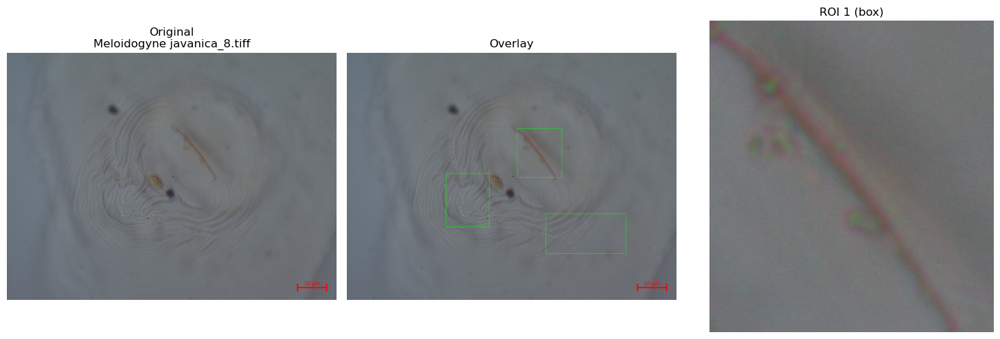

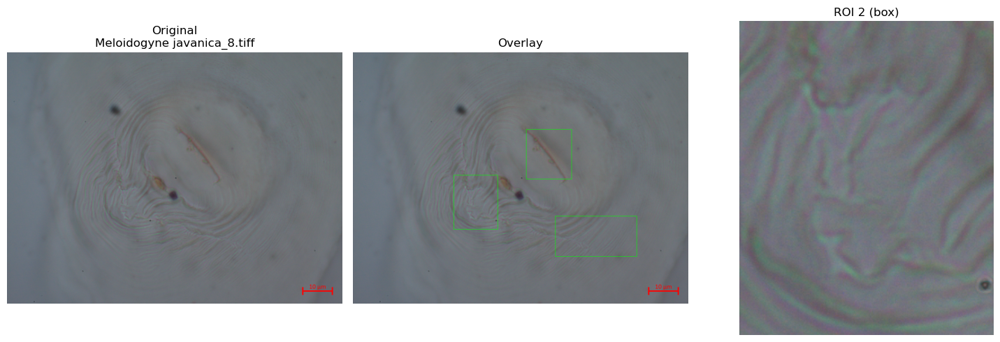

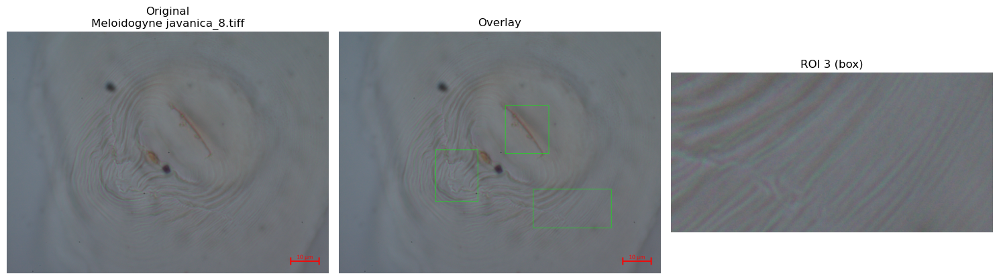

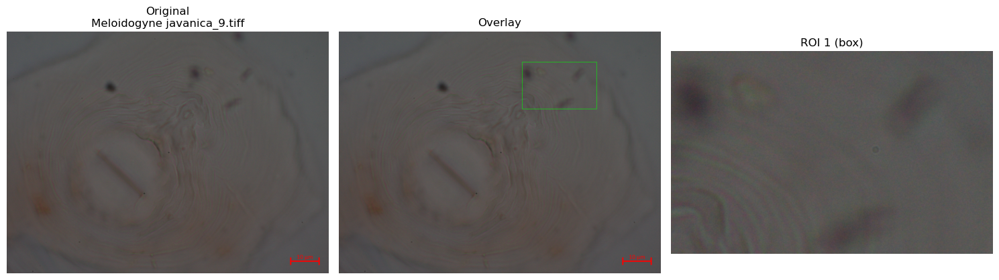

In [4]:
import os
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# PATHS
IMAGE_DIR = "/home/dbtproject/barsha/Image/training_set/Class2_Javanica"
XML_PATH = "/home/dbtproject/barsha/np_code_new/annotations.xml"

# LOAD XML
tree = ET.parse(XML_PATH)
root = tree.getroot()


# OVERLAY FUNCTION

def draw_overlay(image, image_tag):

    overlay = image.copy()

    # RECTANGLES
    for box in image_tag.findall("box"):
        xtl = int(float(box.get("xtl")))
        ytl = int(float(box.get("ytl")))
        xbr = int(float(box.get("xbr")))
        ybr = int(float(box.get("ybr")))

        cv2.rectangle(overlay, (xtl, ytl), (xbr, ybr), (0, 255, 0), 2)

    # ELLIPSES
    for ellipse in image_tag.findall("ellipse"):
        cx = float(ellipse.get("cx"))
        cy = float(ellipse.get("cy"))
        rx = float(ellipse.get("rx"))
        ry = float(ellipse.get("ry"))

        center = (int(cx), int(cy))
        axes = (int(rx), int(ry))

        cv2.ellipse(overlay, center, axes, 0, 0, 360, (0, 255, 0), 2)

    # POLYGONS
    for poly in image_tag.findall("polygon"):
        pts = []
        for p in poly.get("points").split(";"):
            x, y = map(float, p.split(","))
            pts.append([int(x), int(y)])

        pts = np.array(pts, np.int32)
        cv2.polylines(overlay, [pts], True, (0,255,0), 2)

    return overlay



# ROI EXTRACTION FUNCTION

def extract_roi(image, shape):

    H, W = image.shape[:2]

    # RECTANGLE
    if shape.tag == "box":
        xtl = int(float(shape.get("xtl")))
        ytl = int(float(shape.get("ytl")))
        xbr = int(float(shape.get("xbr")))
        ybr = int(float(shape.get("ybr")))

        return image[ytl:ybr, xtl:xbr]

    # ELLIPSE
    elif shape.tag == "ellipse":
        cx = float(shape.get("cx"))
        cy = float(shape.get("cy"))
        rx = float(shape.get("rx"))
        ry = float(shape.get("ry"))

        mask = np.zeros((H, W), dtype=np.uint8)
        cv2.ellipse(mask, (int(cx), int(cy)), (int(rx), int(ry)), 0, 0, 360, 1, -1)

        ys, xs = np.where(mask == 1)
        if len(xs) == 0:
            return None

        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()

        roi = image[y1:y2+1, x1:x2+1]
        mask_crop = mask[y1:y2+1, x1:x2+1]

        roi[mask_crop == 0] = 0
        return roi

    # POLYGON
    elif shape.tag == "polygon":
        pts = []
        for p in shape.get("points").split(";"):
            x, y = map(float, p.split(","))
            pts.append([int(x), int(y)])

        pts = np.array(pts, np.int32)

        mask = np.zeros((H, W), dtype=np.uint8)
        cv2.fillPoly(mask, [pts], 1)

        ys, xs = np.where(mask == 1)
        if len(xs) == 0:
            return None

        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()

        roi = image[y1:y2+1, x1:x2+1]
        mask_crop = mask[y1:y2+1, x1:x2+1]

        roi[mask_crop == 0] = 0
        return roi

    return None


# MAIN LOOP

for image_tag in root.findall("image"):

    file_name = image_tag.get("name")
    img_path = os.path.join(IMAGE_DIR, file_name)

    if not os.path.exists(img_path):
        continue

    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    overlay = draw_overlay(image, image_tag)

    # collect all shapes
    shapes = []
    shapes.extend(image_tag.findall("box"))
    shapes.extend(image_tag.findall("ellipse"))
    shapes.extend(image_tag.findall("polygon"))

  
    # SHOW EACH ROI
 
    for i, shape in enumerate(shapes):

        roi = extract_roi(image.copy(), shape)

        if roi is None:
            continue

        # DISPLAY 3 COLUMNS
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))

        ax[0].imshow(image)
        ax[0].set_title(f"Original\n{file_name}")

        ax[1].imshow(overlay)
        ax[1].set_title("Overlay")

        ax[2].imshow(roi)
        ax[2].set_title(f"ROI {i+1} ({shape.tag})")

        for a in ax:
            a.axis("off")

        plt.tight_layout()
        plt.show()